# 04 - Model Training & Evaluation

### Overview
- Create lag features (lag 7, lag 14, lag 28) and rolling statistics (rolling 7, rolling 28).
- Temporal validation split (last 14 days reserved for holdout evaluation).
- Establish baseline performance using naive Lag-7 persistence.
- Train LightGBM Regressor with early stopping on validation loss.
- Benchmark MAE, RMSE, and RMSLE against baseline.
- Inspect feature importances and serialize trained model to `models/lightgbm_inventory_model.pkl`.


In [6]:
import os
import pandas as pd 
import numpy as np

base_dir = ".." if os.path.exists("../data") else "."
df = pd.read_csv(f"{base_dir}/data/processed/train_features.csv")
df.head()


,id,date,store_nbr,family,sales,onpromotion,year,month,day,week_name,...,is_weekend,city,state,type,cluster,dcoilwtico,has_promotion,promotion_intensity,is_national_holiday,holiday_count
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,...,0,Quito,Pichincha,D,13,93.14,0,0.0,1,1.0
1,1,2013-01-01,1,BABY CARE,0.0,0,2013,1,1,1,...,0,Quito,Pichincha,D,13,93.14,0,0.0,1,1.0
2,2,2013-01-01,1,BEAUTY,0.0,0,2013,1,1,1,...,0,Quito,Pichincha,D,13,93.14,0,0.0,1,1.0
3,3,2013-01-01,1,BEVERAGES,0.0,0,2013,1,1,1,...,0,Quito,Pichincha,D,13,93.14,0,0.0,1,1.0
4,4,2013-01-01,1,BOOKS,0.0,0,2013,1,1,1,...,0,Quito,Pichincha,D,13,93.14,0,0.0,1,1.0


In [7]:
df.shape

(3000888, 23)

In [8]:
df['date']=pd.to_datetime(df['date'])

In [10]:
df = df.sort_values(
    ["store_nbr", "family", "date"]
).reset_index(drop=True)
df.head()

,id,date,store_nbr,family,sales,onpromotion,year,month,day,week_name,...,is_weekend,city,state,type,cluster,dcoilwtico,has_promotion,promotion_intensity,is_national_holiday,holiday_count
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,...,0,Quito,Pichincha,D,13,93.14,0,0.0,1,1.0
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0,2013,1,2,2,...,0,Quito,Pichincha,D,13,93.14,0,0.0,0,0.0
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0,2013,1,3,3,...,0,Quito,Pichincha,D,13,92.97,0,0.0,0,0.0
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0,2013,1,4,4,...,0,Quito,Pichincha,D,13,93.12,0,0.0,0,0.0
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0,2013,1,5,5,...,1,Quito,Pichincha,D,13,93.12,0,0.0,1,1.0


In [12]:
groups = df.groupby(
    ["store_nbr", "family"]
)["sales"]
df["lag_7"] = groups.shift(7)
df["lag_14"] = groups.shift(14)
df["lag_28"] = groups.shift(28)

In [13]:
df["rolling_mean_7"] = (
    df.groupby(["store_nbr", "family"])["sales"]
    .transform(lambda x: x.shift(1).rolling(7).mean())
)

In [14]:
df["rolling_mean_28"] = (
    df.groupby(["store_nbr", "family"])["sales"]
    .transform(lambda x: x.shift(1).rolling(28).mean())
)

In [15]:
df.head(15)

,id,date,store_nbr,family,sales,onpromotion,year,month,day,week_name,...,dcoilwtico,has_promotion,promotion_intensity,is_national_holiday,holiday_count,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,2013,1,1,1,...,93.14,0,0.0,1,1.0,NaN,NaN,NaN,NaN,NaN
1,1782,2013-01-02,1,AUTOMOTIVE,2.0,0,2013,1,2,2,...,93.14,0,0.0,0,0.0,NaN,NaN,NaN,NaN,NaN
2,3564,2013-01-03,1,AUTOMOTIVE,3.0,0,2013,1,3,3,...,92.97,0,0.0,0,0.0,NaN,NaN,NaN,NaN,NaN
3,5346,2013-01-04,1,AUTOMOTIVE,3.0,0,2013,1,4,4,...,93.12,0,0.0,0,0.0,NaN,NaN,NaN,NaN,NaN
4,7128,2013-01-05,1,AUTOMOTIVE,5.0,0,2013,1,5,5,...,93.12,0,0.0,1,1.0,NaN,NaN,NaN,NaN,NaN
5,8910,2013-01-06,1,AUTOMOTIVE,2.0,0,2013,1,6,6,...,93.12,0,0.0,0,0.0,NaN,NaN,NaN,NaN,NaN
6,10692,2013-01-07,1,AUTOMOTIVE,0.0,0,2013,1,7,0,...,93.20,0,0.0,0,0.0,NaN,NaN,NaN,NaN,NaN
7,12474,2013-01-08,1,AUTOMOTIVE,2.0,0,2013,1,8,1,...,93.21,0,0.0,0,0.0,0.0,NaN,NaN,2.142857,NaN
8,14256,2013-01-09,1,AUTOMOTIVE,2.0,0,2013,1,9,2,...,93.08,0,0.0,0,0.0,2.0,NaN,NaN,2.428571,NaN
9,16038,2013-01-10,1,AUTOMOTIVE,2.0,0,2013,1,10,3,...,93.81,0,0.0,0,0.0,3.0,NaN,NaN,2.428571,NaN


In [16]:
df = df.sort_values("date").reset_index(drop=True)

In [17]:
validation_start = df["date"].max() - pd.Timedelta(days=14)

In [18]:
train_data = df[df["date"] < validation_start].copy()
valid_data = df[df["date"] >= validation_start].copy()

In [19]:
train_data["date"].min(), "to", train_data["date"].max()

(Timestamp('2013-01-01 00:00:00'), 'to', Timestamp('2017-07-31 00:00:00'))

In [20]:
valid_data["date"].min(), "to", valid_data["date"].max()

(Timestamp('2017-08-01 00:00:00'), 'to', Timestamp('2017-08-15 00:00:00'))

In [21]:
train_data.shape,valid_data.shape

((2974158, 28), (26730, 28))

In [22]:
drop_columns = ["sales","date","id"]
drop_columns = [
    col for col in drop_columns
    if col in train_data.columns
]

In [23]:
X_train = train_data.drop(columns=drop_columns)
y_train = train_data["sales"]

X_valid = valid_data.drop(columns=drop_columns)
y_valid = valid_data["sales"]

In [24]:
categorical_columns = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

C:\Users\hp\AppData\Local\Temp\ipykernel_4512\1144500732.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(


In [25]:
for col in categorical_columns:
    X_train[col] = X_train[col].astype("category")
    X_valid[col] = pd.Categorical(
        X_valid[col],
        categories=X_train[col].cat.categories
    )
categorical_columns

['family', 'city', 'state', 'type']

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline_predictions = valid_data["lag_7"]
baseline_mask = baseline_predictions.notna()

baseline_actual = y_valid[baseline_mask]
baseline_pred = baseline_predictions[baseline_mask]

baseline_mae = mean_absolute_error(
    baseline_actual,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(baseline_actual, baseline_pred)
)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)

Baseline MAE: 101.25217398060231
Baseline RMSE: 353.8005626822748


In [28]:
import lightgbm as lgb
model = lgb.LGBMRegressor(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="l1",
    categorical_feature=categorical_columns,
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=100)
    ]
)

d:\Store Prdiction\venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
[100]	valid_0's l1: 72.6351	valid_0's l2: 54786.3
Early stopping, best iteration is:
[57]	valid_0's l1: 78.3618	valid_0's l2: 51481.5


,learning_rate,0.05
,n_estimators,1000
,objective,'regression'
,random_state,42
,n_jobs,-1
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,class_weight,None


In [29]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

predictions = model.predict(X_valid)

mae = mean_absolute_error(y_valid,predictions)

rmse = np.sqrt( mean_squared_error(y_valid, predictions))

rmsle = np.sqrt(np.mean((np.log1p(np.maximum(y_valid, 0)) - np.log1p(np.maximum(predictions, 0))) ** 2))

print("LightGBM Results")
print("----------------")
print("MAE:", mae)
print("RMSE:", rmse)
print("RMSLE:", rmsle)

LightGBM Results
----------------
MAE: 78.3617816641991
RMSE: 226.89538759687576
RMSLE: 1.577821095268306


In [31]:
comparison = pd.DataFrame({"Model": ["Baseline (Lag 7)", "LightGBM"],"MAE": [baseline_mae, mae],"RMSE": [baseline_rmse,rmse]})

display(comparison)

,Model,MAE,RMSE
0,Baseline (Lag 7),101.252174,353.800563
1,LightGBM,78.361782,226.895388


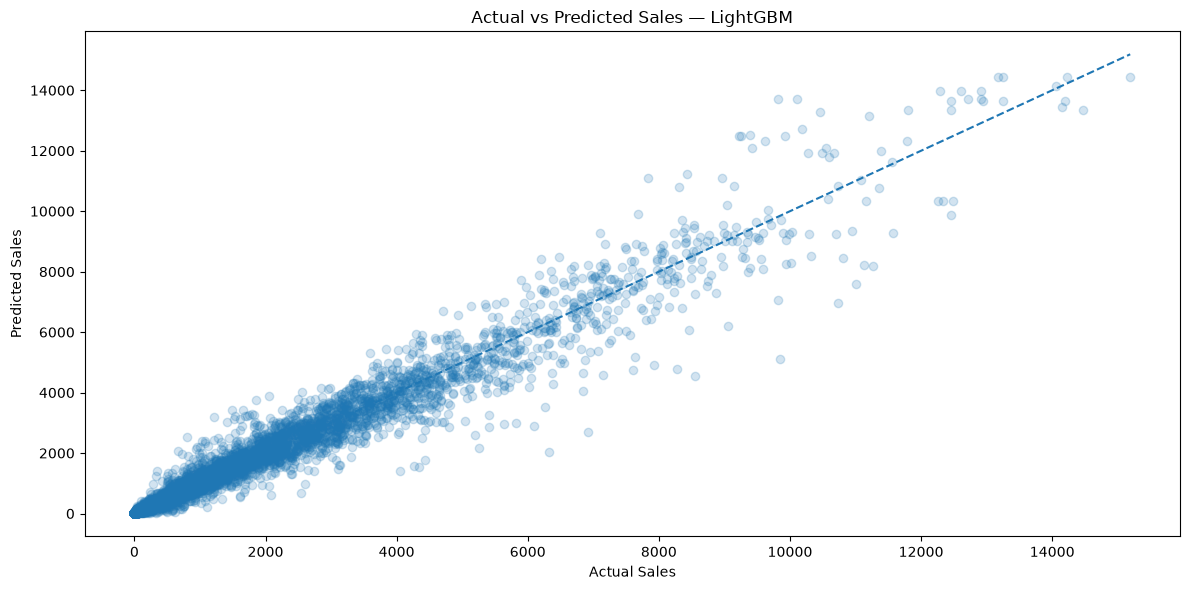

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.scatter(
    y_valid,
    predictions,
    alpha=0.2
)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales — LightGBM")

max_value = max(y_valid.max(), predictions.max())

plt.plot([0, max_value],[0, max_value],linestyle="--")

plt.tight_layout()
plt.show()

                Feature  Importance
23       rolling_mean_7         327
5                   day         233
20                lag_7         200
21               lag_14         161
7             year_name         143
6             week_name         139
22               lag_28         131
2           onpromotion         103
1                family          52
8          week_of_year          52
18  is_national_holiday          51
0             store_nbr          38
15           dcoilwtico          22
4                 month          16
24      rolling_mean_28          15


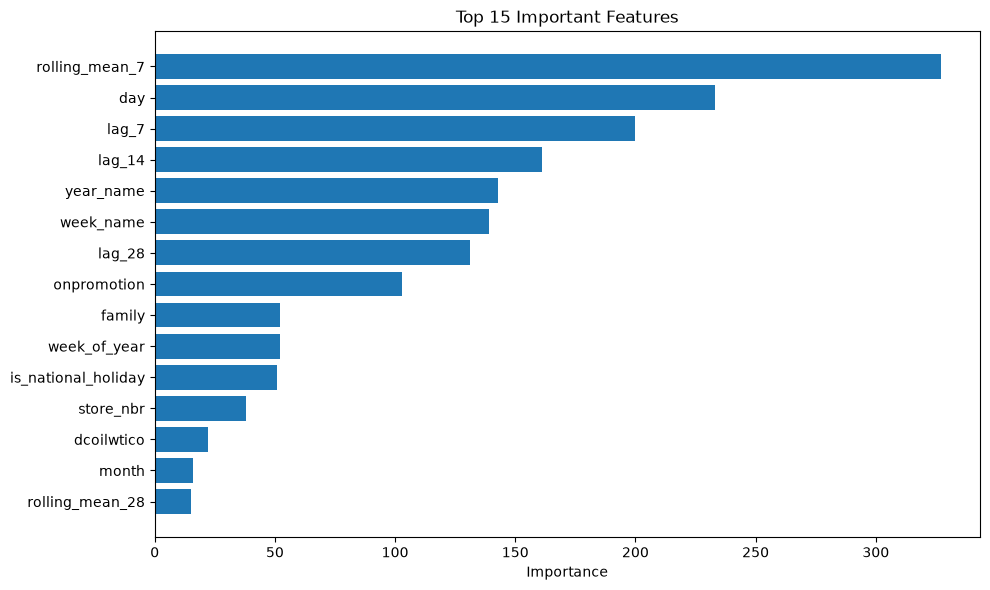

In [33]:
feature_importance = pd.DataFrame({"Feature": X_train.columns,"Importance": model.feature_importances_})
feature_importance = feature_importance.sort_values(by="Importance",ascending=False)

print(feature_importance.head(15))

plt.figure(figsize=(10, 6))

top_features = feature_importance.head(15)

plt.barh(top_features["Feature"],top_features["Importance"])

plt.gca().invert_yaxis()

plt.title("Top 15 Important Features")
plt.xlabel("Importance")

plt.tight_layout()
plt.show()

In [ ]:
import joblib
import os

model_dir = f"{base_dir}/models"
os.makedirs(model_dir, exist_ok=True)

joblib.dump(
    model,
    f"{model_dir}/lightgbm_inventory_model.pkl"
)

print("Model saved successfully!")


Model saved successfully!
